# Arizona Gobernador 2026 · Modelo final (general)
**Katie Hobbs (D) vs Andy Biggs (R)**, más Teri Hourihan (No Labels) y Risa Lombardo (Green). Elección: 3-nov-2026. Corte: 21-oct-2026.

Modelo elegido por backtest (`../backtest`): base **Georgia V11 sin sesgo estatal**, más la capa de **terceros calibrada**, que viene de la primaria de Arizona. Indecisos 50/50. Mercados (Kalshi + Polymarket) con peso 0.30.

| Pieza | Origen | Evidencia (CRPS LOYO, menor = mejor) |
|---|---|---|
| Promedio con efectos de casa, √n, vida media 14 d, 1 voto por firma | Georgia V11 | Nacional 3.495, mejor que todas las variantes |
| Sin sesgo estatal | Hallazgo AZ | AZ 2.471 contra 2.630 con sesgo; error relativo de AZ sin persistencia (corr −0.11) |
| Terceros = 1.87 + 0.69 × encuestas | Primaria AZ (terceros nombrados) | MAE % D: 3.08 → 2.56 nacional; 2.53 → 1.94 AZ |
| σ calibrada + colas t | Georgia V11 | Dirichlet + shocks de la primaria: peor (P mejor 0.00 nacional) |
| Indecisos 50/50 | Georgia V11 | Escenarios de la primaria: 3.579; proporcional: 3.759 |

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import arizona_modelo_final as am
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 50)
cfg = am.Config()
r = am.ejecutar(cfg)
f = r['resultado']
print(f"Corte {cfg.corte} · {cfg.dias_a_eleccion} días a la elección")
print(f"Hobbs {f['Hobbs']:.1f}% (IC80 {f['Hobbs_IC80'][0]:.1f}–{f['Hobbs_IC80'][1]:.1f}) · Biggs {f['Biggs']:.1f}% "
      f"(IC80 {f['Biggs_IC80'][0]:.1f}–{f['Biggs_IC80'][1]:.1f}) · Terceros {f['Terceros']:.1f}%")
print(f"Margen Hobbs−Biggs {f['margen_media']:+.1f} pp (σ {f['sd']:.1f}) · IC95 {f['IC95_margen'][0]:+.1f} a {f['IC95_margen'][1]:+.1f}")
print(f"P(Hobbs) = {f['P_Hobbs']:.1%} (solo encuestas {f['P_Hobbs_modelo']:.1%}; mercados {r['mercados']['promedio_D']:.1%}) · "
      f"P(recuento automático, margen ≤ 0.5) = {f['P_recuento']:.1%}")

Corte 2026-10-21 · 13 días a la elección
Hobbs 51.8% (IC80 48.4–55.2) · Biggs 44.2% (IC80 40.8–47.6) · Terceros 4.1%
Margen Hobbs−Biggs +7.6 pp (σ 5.1) · IC95 -2.6 a +17.7
P(Hobbs) = 93.5% (solo encuestas 94.1%; mercados 92.1%) · P(recuento automático, margen ≤ 0.5) = 2.3%


## Encuestas 2026 (Wikipedia + tu Excel + 270toWin, sin duplicados)
Prioridad: Wikipedia (fechas de campo exactas) > Excel > 270toWin (fecha de publicación). `tambien_en` = otras fuentes donde aparece la misma encuesta.

In [2]:
t = r['encuestas_todas']
t[['pollster','inicio','fin','n','pop','D','R','otros','origen','tambien_en','en_ventana']].assign(fin=t.fin.dt.date)

,pollster,inicio,fin,n,pop,D,R,otros,origen,tambien_en,en_ventana
0,Fabrizio Ward (R)/ Impact Research (D),2026-07-26,2026-07-28,913.0,LV,52.0,44.0,0.0,wikipedia,"270towin, excel",False
1,The Tarrance Group (R),2026-07-27,2026-07-30,600.0,LV,52.0,48.0,0.0,wikipedia,excel,False
2,Grayhouse (R),2026-08-09,2026-08-11,600.0,LV,49.0,45.0,0.0,wikipedia,excel,False
3,Noble Predictive Insights,2026-08-10,2026-08-13,923.0,LV,48.0,35.0,4.0,wikipedia,"270towin, excel",False
4,Stealth Analytics,2026-08-11,2026-08-13,530.0,LV,43.0,38.0,1.0,wikipedia,"270towin, excel",False
5,Kreate Strategies (R),2026-08-13,2026-08-16,900.0,LV,45.0,40.0,3.0,wikipedia,excel,False
6,Quantus Insights (R),2026-08-14,2026-08-17,780.0,LV,49.0,43.0,2.0,wikipedia,"270towin, excel",False
7,HighGround,2026-08-15,2026-08-18,400.0,LV,49.5,34.3,NaN,excel,270towin,False
8,NextGen Polling (R),2026-08-17,2026-08-19,1627.0,LV,39.0,38.0,2.0,wikipedia,"270towin, excel",False
9,Arizona State University,2026-08-18,2026-09-04,1300.0,RV,47.0,34.0,3.0,wikipedia,"270towin, excel",False


## Ventana y pesos
No hay encuestas en los últimos 21 días (la más reciente terminó el 8-oct). Se usan los 21 días previos a la encuesta más reciente, la misma estructura que el backtest, y se suma la deriva por encuestas viejas (0.25 pp/día, supuesto de California M5).

In [3]:
print(r['ventana'], '· encuestadoras:', r['k'], '· días extra:', r['dias_extra_encuestas'])
print({k: round(v, 3) for k, v in r['parametros'].items() if isinstance(v, float)})
r['encuestas_ventana'][['pollster','fin','n','D','R','otros','efecto_casa','margen_corregido','peso']].round(3)

{'ventana_desde': '2026-09-17', 'ampliada': True, 'regla': 'desplazada'} · encuestadoras: 4 · días extra: 13
{'tau': 3.05, 's': 8.0, 'nu': 12.7, 'terceros_a': 1.873, 'terceros_c': 0.692, 'terceros_sd': 1.903, 'sesgo_az_bruto': 1.637, 'sesgo_az_contraido': 1.427}


,pollster,fin,n,D,R,otros,efecto_casa,margen_corregido,peso
11,GQR (D),2026-10-05,600.0,49.0,45.0,3.0,1.924,2.076,0.212
12,Wick (R),2026-10-06,1513.0,49.0,43.0,3.0,-1.423,7.423,0.353
13,GrayHouse (R),2026-10-08,550.0,50.0,44.0,2.0,0.000,6.000,0.235
14,"HighGround, Inc.",2026-10-08,400.0,51.0,34.0,5.0,0.111,16.889,0.200


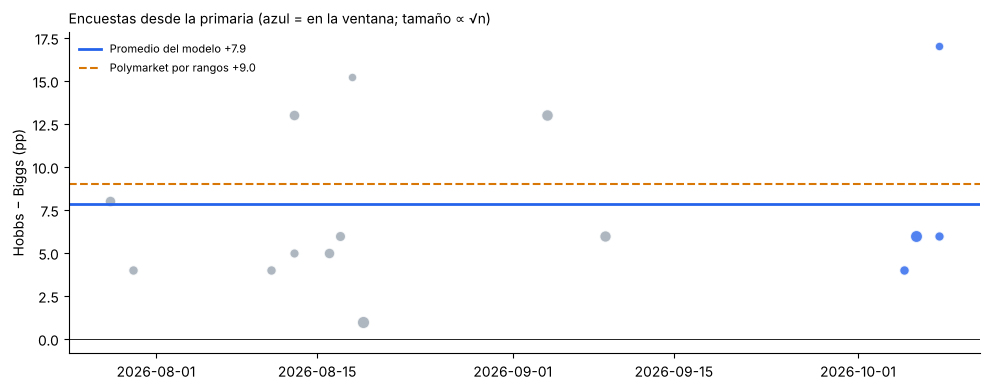

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
for _, x in t.iterrows():
    c = '#2563eb' if x.en_ventana else '#9aa5b1'
    ax.scatter(x.fin, x.D - x.R, s=np.sqrt(x.n) * 2, color=c, alpha=.8, edgecolor='white')
ax.axhline(r['mu'], color='#2563eb', lw=2, label=f"Promedio del modelo {r['mu']:+.1f}")
ax.axhline(r['mercados']['polymarket_rangos_margen_media'], color='#d97706', ls='--',
           label=f"Polymarket por rangos {r['mercados']['polymarket_rangos_margen_media']:+.1f}")
ax.axhline(0, color='k', lw=.6); ax.set_ylabel('Hobbs − Biggs (pp)')
ax.set_title('Encuestas desde la primaria (azul = en la ventana; tamaño ∝ √n)', loc='left', fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(cfg.salida / 'encuestas_y_promedio.png', dpi=130)

## Escenarios de sensibilidad

Cada escenario es una corrida aparte para comparar; **ninguno cambia el pronóstico FINAL** (primera fila).

- **Ajuste partidista (patrocinador D/R):** a cada encuesta con patrocinador D o R se le resta el sesgo medio histórico de su patrocinador (538, contraído k=8), en lugar del efecto de su firma. Bipartidistas (Fabrizio Ward/Impact) y no partidistas: 0.
- **Efecto de casa + partidista si la firma no tiene historia:** igual que el FINAL, pero las firmas sin historia (p. ej. GrayHouse) reciben el efecto de su patrocinador en vez de 0.

No están en el FINAL porque en el backtest LOYO (782 contiendas) no mejoran: CRPS nacional 3.579 (partidista) y 3.562 vs 3.545 sin efectos de casa y 3.561 con efecto por firma; en AZ (22 contiendas) la diferencia no es significativa (P = 0.67).

In [5]:
e = r['escenarios'].copy()
for c in e.columns:
    if c != 'escenario': e[c] = e[c].map(lambda v: tuple(round(x, 1) for x in v) if isinstance(v, tuple) else v)
e[['escenario','margen_media','sd','IC80_margen','Hobbs','Biggs','Terceros','P_Hobbs','P_recuento']].round(3)

,escenario,margen_media,sd,IC80_margen,Hobbs,Biggs,Terceros,P_Hobbs,P_recuento
0,FINAL: encuestas + mercados (Kalshi y Polymarket),7.580,5.109,"(1.2, 13.9)",51.751,44.171,4.078,0.935,0.023
1,Solo encuestas (sin mercados),7.835,5.109,"(1.5, 14.2)",51.878,44.044,4.078,0.941,0.021
2,"Con sesgo estatal AZ (V11, +1.43 pp)",6.426,5.117,"(0.1, 12.8)",51.170,44.744,4.086,0.903,0.033
3,Distribución normal,7.835,5.097,"(1.3, 14.4)",51.877,44.042,4.081,0.938,0.023
4,Sin terceros (como Georgia),7.838,5.116,"(1.5, 14.2)",53.869,46.031,0.100,0.940,0.021
5,Sin deriva por encuestas viejas,7.842,5.021,"(1.6, 14.1)",51.883,44.041,4.075,0.943,0.021
6,Regla literal V11 (última encuesta de cada fir...,11.005,6.500,"(3.0, 19.1)",53.392,42.387,4.220,0.956,0.013
7,Ventana 45 días (4 encuestadoras),7.853,5.102,"(1.5, 14.2)",51.890,44.036,4.074,0.941,0.021
8,Ventana 60 días (6 encuestadoras),7.898,4.549,"(2.3, 13.5)",51.994,44.096,3.909,0.959,0.017
9,Sin efectos de casa,7.791,5.122,"(1.4, 14.2)",51.859,44.068,4.073,0.939,0.022


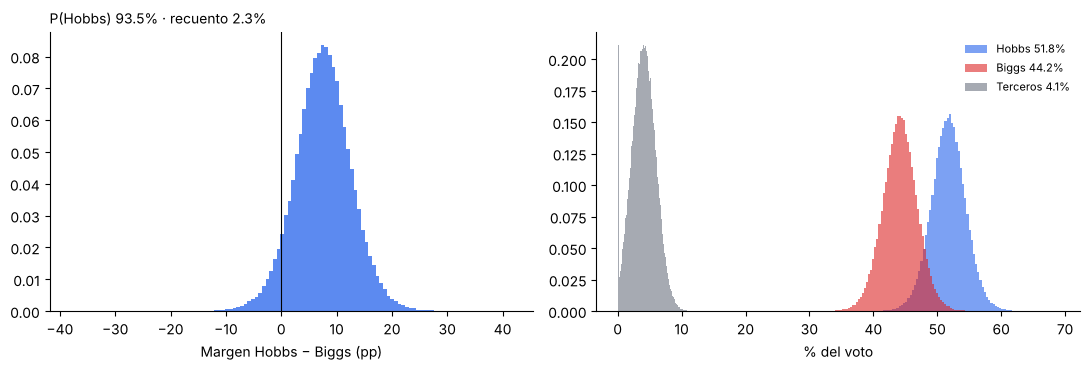

In [6]:
s = r['simulacion']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(s.Margen, bins=120, color='#2563eb', alpha=.75, density=True)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_xlabel('Margen Hobbs − Biggs (pp)')
ax[0].set_title(f"P(Hobbs) {f['P_Hobbs']:.1%} · recuento {f['P_recuento']:.1%}", loc='left', fontsize=10)
for c, col in (('Hobbs', '#2563eb'), ('Biggs', '#dc2626'), ('Terceros', '#6b7280')):
    ax[1].hist(s[c], bins=120, alpha=.6, color=col, density=True, label=f"{c} {s[c].mean():.1f}%")
ax[1].set_xlabel('% del voto'); ax[1].legend(frameon=False, fontsize=8)
for a in ax: a.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(cfg.salida / 'pronostico_arizona.png', dpi=130)

## Kalshi vs Polymarket: ¿son lo mismo?
No del todo. Se mueven juntos en el nivel (correlación 0.96 en gobernador 2026), pero **no en los cambios diarios** (0.16): cada uno tiene ruido propio, y Polymarket es menos líquido (~USD 120 mil en el mercado de gobernador). La diferencia media es de 3.3 pp, con picos de hasta 19 pp. Ninguno se mueve antes que el otro de forma consistente. En 2024 (presidente y Senado AZ, últimos 30 días) Polymarket tuvo un Brier un poco mejor (0.086/0.035 contra 0.100/0.044), pero con n = 2 no es evidencia. **Decisión:** promediar los dos para reducir el ruido propio de cada uno. Polymarket además tiene un mercado por **rangos de margen** que da una distribución completa (media +9.0, DE 6.2).

contienda,Gobernador AZ 2026,Presidente AZ 2024,Senado AZ 2024
dias_comunes,337,28,28
desde,2025-10-15,2024-10-08,2024-10-08
hasta,2026-10-21,2024-11-04,2024-11-04
kalshi_ultimo,0.9064,0.2886,0.7574
polymarket_ultimo,0.935,0.25,0.7817
dif_media_pp,-2.5887,2.1511,-2.3295
dif_abs_media_pp,3.2961,2.163,2.7136
dif_abs_max_pp,19.1966,7.5,5.5
dif_abs_ult30_pp,1.338,2.163,2.7136
corr_niveles,0.9578,0.8771,0.8968


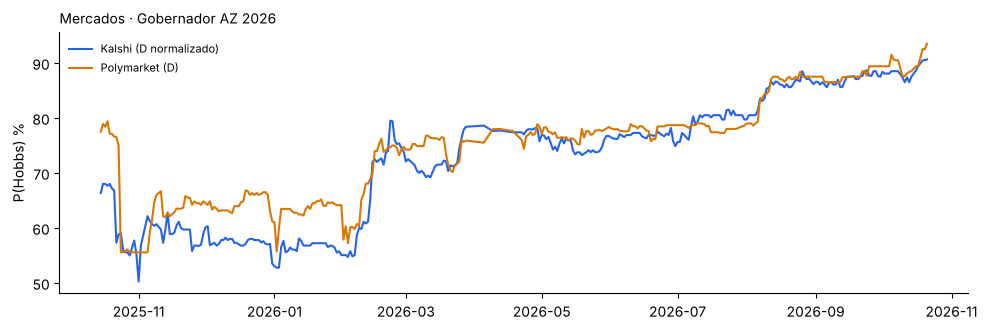

In [7]:
m = pd.read_csv('../backtest/salida/mercados_comparacion.csv'); display(m.set_index('contienda').T)
x = pd.read_csv(am.DATA / 'mercados_az_gob2026_diario.csv', parse_dates=['fecha'])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(x.fecha, 100 * x.kalshi, label='Kalshi (D normalizado)', color='#2563eb')
ax.plot(x.fecha, 100 * x.polymarket, label='Polymarket (D)', color='#d97706')
ax.set_ylabel('P(Hobbs) %'); ax.legend(frameon=False, fontsize=8); ax.spines[['top','right']].set_visible(False)
ax.set_title('Mercados · Gobernador AZ 2026', loc='left', fontsize=10)
fig.tight_layout(); fig.savefig(cfg.salida / 'kalshi_vs_polymarket.png', dpi=130)

## Backtest (resumen)
Detalle y código en `../backtest` (`python backtest_arizona.py`).

In [8]:
R = pd.read_csv('../backtest/salida/metricas_margen.csv')
display(R.pivot(index='modelo', columns='ambito', values='CRPS').round(3).sort_values('Nacional'))
display(pd.read_csv('../backtest/salida/bootstrap_vs_V11.csv').pivot(index='variante', columns='ambito', values='P(variante mejor que V11)').round(3))
T = pd.read_csv('../backtest/salida/metricas_porcentajes.csv')
T[T.modelo.str.startswith('G')].drop(columns='modelo').round(2)

ambito,AZ_2016+,AZ_todas,Nacional,Nacional_Gob
modelo,,,,
G Georgia V11,2.794,2.630,3.495,3.677
H6 V11 con vida media 10 d,2.815,2.643,3.501,3.679
H5 Pesos de la primaria + resto V11,2.786,2.643,3.502,3.677
H7 V11 con pesos ∝ n,2.812,2.607,3.510,3.685
H3 V11 + cuota R de indecisos estimada,2.813,2.686,3.522,3.717
H4 V11 + Dirichlet y shocks de la primaria,2.759,2.599,3.531,3.694
H8 V11 sin sesgo estatal,2.483,2.471,3.561,3.629
H1 V11 + escenarios de indecisos de la primaria,2.843,2.904,3.579,3.812
A Primaria AZ (tal cual),2.544,2.718,3.647,3.775


ambito,AZ_todas,Nacional
variante,,
A Primaria AZ (tal cual),0.380,0.023
H1 V11 + escenarios de indecisos de la primaria,0.050,0.094
H2 V11 + indecisos proporcionales,0.019,0.000
H3 V11 + cuota R de indecisos estimada,0.232,0.296
H4 V11 + Dirichlet y shocks de la primaria,0.754,0.000
H5 Pesos de la primaria + resto V11,0.464,0.405
H6 V11 con vida media 10 d,0.204,0.010
H7 V11 con pesos ∝ n,0.779,0.064
H8 V11 sin sesgo estatal,0.854,0.160


,ambito,regla,n,MAE_%D,MAE_%R,MAE_terceros,sesgo_terceros
0,Nacional,T0 terceros = 0 (Georgia),782,3.08,2.56,2.76,-2.76
1,Nacional,T1 terceros = lo que dicen las encuestas (prim...,782,2.74,2.48,1.80,-1.48
2,Nacional,T2 terceros calibrados a + c·encuesta (LOYO),782,2.56,2.49,1.44,-0.00
3,Nacional,T3 terceros = media histórica del estado (pasado),782,2.76,2.52,1.90,-0.01
8,AZ_todas,T0 terceros = 0 (Georgia),22,2.53,2.07,2.97,-2.97
9,AZ_todas,T1 terceros = lo que dicen las encuestas (prim...,22,2.04,1.93,1.54,-1.16
10,AZ_todas,T2 terceros calibrados a + c·encuesta (LOYO),22,1.94,1.98,1.25,0.15
11,AZ_todas,T3 terceros = media histórica del estado (pasado),22,2.14,1.94,1.95,0.62
16,Con terceros > 3%,T0 terceros = 0 (Georgia),266,4.18,2.90,5.45,-5.45
17,Con terceros > 3%,T1 terceros = lo que dicen las encuestas (prim...,266,3.32,2.68,3.24,-2.66


## Voto anticipado en vivo (civicAPI · diagnóstico)
Boletas anticipadas solicitadas y devueltas, por partido y condado, de [civicAPI](https://civicapi.org), que las recopila de las autoridades electorales. Es gratis y sin clave, con atribución. Si la API falla, se usa el último snapshot guardado en `datos/civicapi/`. Cada corrida agrega un día a `datos/civicapi/historial_az.csv`, una serie propia para comparar al mismo día en 2028. **No entra al pronóstico**: en Georgia y California la composición del voto anticipado no mejoró el error fuera de muestra.

In [9]:
va = r['voto_anticipado']
if va['disponible']:
    print(f"{va['fecha']} · {va['estado']} · devueltas {va['devueltas']:,} de {va['solicitadas']:,} solicitadas")
    print(f"Devueltas: D {va['pct_dev_D']:.1f}% · R {va['pct_dev_R']:.1f}% · otros {va['pct_dev_otros']:.1f}% (D−R {va['margen_dev_DR_pp']:+.1f})")
    print(f"Tasa de devolución: D {va['tasa_dev_D']:.1f}% · R {va['tasa_dev_R']:.1f}% · otros {va['tasa_dev_otros']:.1f}% · Maricopa {va['maricopa_pct_dev']:.1f}% de lo devuelto")
    display(va['condados'][['condado','devueltas','margen_dev_DR_pp']].round(1))
    display(va['historial'])

2026-10-21 · snapshot guardado (ProxyError: HTTPSConnectionPool(host='civicapi.org', port=443): Max retries exceeded with ur) · devueltas 642,253 de 3,262,834 solicitadas
Devueltas: D 39.2% · R 38.2% · otros 22.6% (D−R +0.9)
Tasa de devolución: D 24.0% · R 21.3% · otros 13.6% · Maricopa 59.7% de lo devuelto


,condado,devueltas,margen_dev_DR_pp
0,Maricopa,383527,0.8
1,Pima,99852,24.3
2,Pinal,40197,-7.6
3,Yavapai,40150,-24.0
4,Mohave,22042,-39.3
5,Coconino,14849,28.7
6,Cochise,13920,-5.3
7,Yuma,11342,-6.4
8,Gila,7525,-29.9
9,Navajo,3151,-5.4


,fecha,devueltas,solicitadas,pct_dev_D,pct_dev_R,pct_dev_otros,margen_dev_DR_pp,tasa_dev_D,tasa_dev_R,tasa_dev_otros,maricopa_pct_dev
0,2026-10-21,642253,3262834,39.172725,38.225279,22.601996,0.947446,24.024346,21.329021,13.635548,59.715875


## Errores históricos en Arizona y electorado 2026 (diagnóstico)
En Arizona el error de las encuestas alterna de signo: sobrestimaron a los demócratas en años presidenciales (2016, 2020, 2024) y los subestimaron en las intermedias de 2018 y 2022. Por eso el sesgo estatal no funciona en AZ. El voto anticipado y el registro son **diagnóstico**: no entran al pronóstico, porque en Georgia y California no mejoraron el error fuera de muestra.

In [10]:
display(r['errores_az'])
r['diagnostico']

,race,year,location,k,otros_enc,otros_real,e
0,1998_Gov-G_AZ,1998,AZ,2,0.000,3.52,3.730
1,1998_Sen-G_AZ,1998,AZ,2,0.000,4.07,-5.021
2,2000_Pres-G_AZ,2000,AZ,2,1.494,4.24,-5.382
3,2002_Gov-G_AZ,2002,AZ,3,6.785,8.59,5.102
4,2004_Pres-G_AZ,2004,AZ,3,0.343,0.73,2.107
5,2006_Gov-G_AZ,2006,AZ,2,0.508,1.98,-1.737
6,2006_Sen-G_AZ,2006,AZ,2,1.524,3.16,2.484
7,2008_Pres-G_AZ,2008,AZ,1,2.000,1.24,6.226
8,2010_Gov-G_AZ,2010,AZ,1,3.000,3.20,-3.231
9,2012_Pres-G_AZ,2012,AZ,1,0.000,1.75,2.063


,indicador,valor,fecha,fuente
0,registro_republicanos_pct,34.81,2026-10-20,Arizona SOS vía FOX 10 (registro final para la...
1,registro_democratas_pct,28.33,2026-10-20,Arizona SOS vía FOX 10
2,registro_otros_independientes_pct,34.92,2026-10-20,Arizona SOS vía FOX 10
3,registro_no_labels_pct,1.12,2026-10-20,Arizona SOS vía FOX 10
4,registro_libertario_pct,0.69,2026-10-20,Arizona SOS vía FOX 10
5,registro_verde_pct,0.13,2026-10-20,Arizona SOS vía FOX 10
6,registro_total,4374827.00,2026-10-20,Arizona SOS vía FOX 10
7,anticipado_devueltas,259584.00,2026-10-16,Derek Weech (Substack) con datos de condados
8,anticipado_dem_pct,40.80,2026-10-16,Derek Weech
9,anticipado_rep_pct,36.90,2026-10-16,Derek Weech
